### Restrictions:
• Maximum 5,000 words in Markdown cells throughout the notebook
<br>• Maximum 100 words per Markdown cell.
<br>• Maximum 30 lines of code per code block, excluding blank lines.
<br>• Maximum 15 figures throughout the notebook.
<br>• Report only the top 5 hyperparameter configuration results for each model.
<br>• Do not include comments within code blocks. Explanations of the code should be
provided in the corresponding Markdown cells instead.

# Description of the dataset

State a brief description of the dataset.
<br>• Provide a description of the collection process executed to build the dataset. Note that
you may need to look at relevant sources related to the dataset to acquire necessary
information for this part of the project.
<br>• Describe the structure of the dataset file.
<br>o What does each row and column represent?
<br>o How many instances are there in the dataset?
<br>o How many features are there in the dataset?
<br>o If the dataset is composed of different files that you will combine in the succeeding
steps, describe the structure and the contents of each file.
<br>• Discuss the features in each dataset file. What does each feature represent? All features,
even those which are not used for the study, should be described to the reader. The
purpose of each feature in the dataset should be clear to the reader of the notebook
without having to go through an external link.

# List of requirements

In [1]:
from encodings import mac_latin2
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
SEED = 55

Import libraries for loading and cleaning data as well as splitting the dataset

# Data Cleaning, Preprocessing and EDA

## Cleaning

In [2]:
raw = pd.read_csv("dataset_Cheat_Detection.csv", sep=";", decimal=",")

Read the file and define that ; is a separator and , is the decimal point because the dataset has European format

In [3]:
cleaned = raw.drop(columns=['timestamp', 'isAimbot_max', 'isVidaInfinita_max', 'isMunicionInfinita_max', 'isSuperVelocidad_max'])

Remove the **Timestamp** Column because nearly every row has a unique value, so it works more as an identifier rather than a feature. The model may end up learning a time-based pattern instead of looking at the other feature values to decide whether cheating occurred or not.

**isAimbot_max, isVidaInfinita_max, isMunicionInfinita_max, and isSuperVelocidad_max** were also removed because they are sub-labels of **es_trampa_max**, which is 1 (Cheating) whenever at least one of them is true. Keeping them would leak the target to the model, and they would not be available in a real-world scenario.

In [4]:
cleaned.isna().sum()

angle_error_mean          0
angle_error_max           0
speed_mean                0
speed_max                 0
is_shot_sum               0
is_hit_sum                0
is_received_damage_sum    0
health_mean               0
ammo_left_min             0
ammo_max                  0
es_trampa_max             0
accuracy_rate             0
infinite_ammo_ratio       0
dtype: int64

Check if there are any cells with missing values that may affect the model's training or lead to errors during preprocessing.

In [5]:
dup_count = cleaned.duplicated().sum()
print ("Duplicates: ", dup_count)
if dup_count > 0:   
    cleaned.drop_duplicates(subset=None, inplace=True)

print(f'Before: {len(raw)} rows')
print(f'Target: {len(cleaned)} rows')

Duplicates:  60
Before: 3584 rows
Target: 3524 rows


Check if there are any duplicated rows that could lead to the model developing a bias and also preventing a leakage. There were 60 duplicates found since we removed the Timestamp column.


In [6]:
features = cleaned.drop(columns = "es_trampa_max")

print("Min:", features.min().min())
print("Max:", features.max().max())
print("All features in [0,1]:", ((features >= 0) & (features <= 1)).all().all(), "\n")

print("Label values:", sorted(cleaned["es_trampa_max"].unique()), "\n")

Min: 0.0
Max: 1.0
All features in [0,1]: True 

Label values: [np.float64(0.0), np.float64(1.0)] 



Checked for misrepresented values. All features fall within [0, 1], showing the data was already scaled by the source, and the label only contains 0 and 1. No invalid values were found.

## Pre-Processing

In [7]:
cleaned["es_trampa_max"] = cleaned["es_trampa_max"].astype(int)
print(cleaned["es_trampa_max"].dtype)

int64


The label es_trampa_max was stored as a decimal (0.0 or 1.0). It was changed to a whole number (0 or 1) because it only marks two groups, Not Cheating (0) and Cheating (1), rather than measuring an amount.

In [8]:
cleaned.to_csv("cleanedDataset.csv", index=False)

Save changes to the cleaned csv file. Below is the list of Pre-Processing techniques that were not applied:

Normalization: all features are already scaled to [0, 1]

One-hot encoding: Features are numeric, with no categorical columns.

Feature engineering: accuracy_rate (hits ÷ shots) and infinite_ammo_ratio (share of records where ammo didn't decrease) were provided by the source, so no new features were created.

Outliers: Extreme values come from Cheaters, removing them would delete the patterns the model needs to learn.

Standardization: Not applied at this stage. It will be fitted on the training set only, after splitting, to prevent data leakage.

## Exploratory Data Analysis

### Raw vs Cleaned

In [9]:
rawAnalysis = raw.describe()
cleanedAnalysis = cleaned.describe()

compare = pd.concat([rawAnalysis, cleanedAnalysis], axis = 1, keys=['Raw Dataset', 'Cleaned Dataset'])
compare = compare.swaplevel(0, 1, axis = 1).sort_index(axis = 1)

print(compare, "\n\n")

        accuracy_rate                ammo_left_min               \
      Cleaned Dataset  Raw Dataset Cleaned Dataset  Raw Dataset   
count     3524.000000  3584.000000     3524.000000  3584.000000   
mean         0.460943     0.453227        0.360510     0.355521   
std          0.380616     0.382022        0.407238     0.406748   
min          0.000000     0.000000        0.000000     0.000000   
25%          0.000000     0.000000        0.000000     0.000000   
50%          0.454545     0.440972        0.125000     0.125000   
75%          0.818182     0.800000        0.750000     0.750000   
max          1.000000     1.000000        1.000000     1.000000   

             ammo_max              angle_error_max               \
      Cleaned Dataset  Raw Dataset Cleaned Dataset  Raw Dataset   
count     3524.000000  3584.000000     3524.000000  3584.000000   
mean         0.596481     0.587542        0.130310     0.128129   
std          0.403681     0.407235        0.253426     0.2518

A summary analysis using describe() was implemented for both the Raw and Cleaned datasets to compare changes. The table confirms that the statistics are nearly unchanged. Every feature's mean shifted less than 0.01, and the standard deviations change by less than 0.004. The medians stayed relatively the same. Therefore, removing the duplicate rows and irrelevant columns did not distort the distribution of the features and the balance between classes.

### Label Counts

In [10]:
label = 'es_trampa_max'
raw_counts = raw[label].value_counts()
cleaned_counts = cleaned[label].value_counts()

raw_pct = raw[label].value_counts(normalize=True) * 100
cleaned_pct = cleaned[label].value_counts(normalize=True) * 100

label_compare = pd.concat([raw_counts, raw_pct, cleaned_counts, cleaned_pct], axis=1, keys=['Raw Count', 'Raw %', 'Cleaned Count', 'Cleaned %'])

print(label_compare, "\n\n")

               Raw Count      Raw %  Cleaned Count  Cleaned %
es_trampa_max                                                
0.0                 1851  51.646205           1814  51.475596
1.0                 1733  48.353795           1710  48.524404 




The label **es_trampa_max** values were also counted and showed that the ratio of Cheating and Not Cheating classes were preserved. Cheating went from 48.35% in the Raw Dataset to 48.52% in the Cleaned Dataset. Accuracy would also be a reliable evaluation metric.

### Class Means

In [11]:
rawClassMeans = raw[cleaned.columns].groupby("es_trampa_max").mean(numeric_only=True).T
cleanedClassMeans = cleaned.groupby("es_trampa_max").mean().T

classCompare = pd.concat([rawClassMeans, cleanedClassMeans], axis=1,
                         keys=["Raw Dataset", "Cleaned Dataset"])

print(classCompare)

                       Raw Dataset           Cleaned Dataset          
es_trampa_max                  0.0       1.0             0.0       1.0
angle_error_mean          0.009880  0.178873        0.010081  0.181279
angle_error_max           0.015114  0.248839        0.015423  0.252186
speed_mean                0.169654  0.246702        0.173115  0.250020
speed_max                 0.126920  0.160108        0.129509  0.162262
is_shot_sum               0.276661  0.397923        0.282194  0.403275
is_hit_sum                0.147350  0.250294        0.150355  0.253660
is_received_damage_sum    0.050356  0.090226        0.051383  0.091439
health_mean               0.851300  0.933011        0.849149  0.932286
ammo_left_min             0.210798  0.510098        0.213031  0.516959
ammo_max                  0.510974  0.669323        0.519329  0.678326
accuracy_rate             0.375559  0.536183        0.383219  0.543395
infinite_ammo_ratio       0.037114  0.271552        0.037761  0.275205


Calculates the average of each feature for Cheating and Not Cheating players, in both datasets. It shows us which features differ the most between the two classes, and confirms that cleaning didn't change those differences.

Gap between Classes: The mean for Cheaters is much higher on multiple features compared to Non-Cheaters. The largest differences are:
       <br>a. **ammo_left_min** (0.517 vs 0.213)\
       b. **infinite_ammo_ratio** (0.275 vs 0.038)\
       c. **angle_error_max** (0.252 vs 0.015)\
    These three feature may be the biggest indicators for Cheating, which suggests the model can perform well

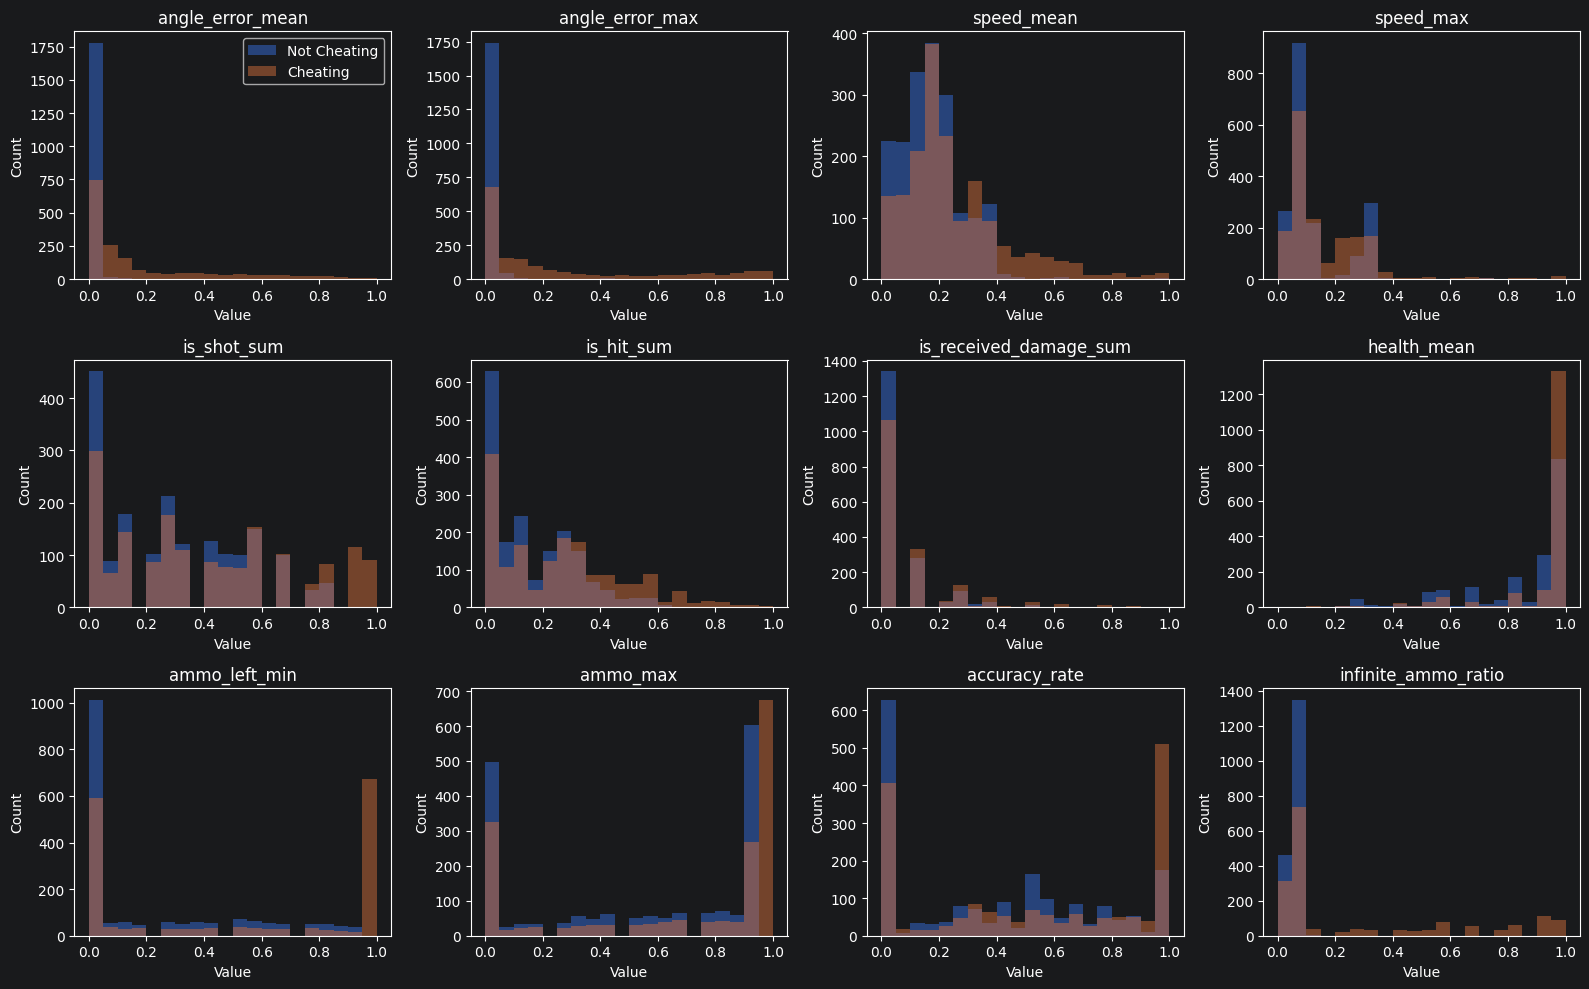

In [12]:
featureCols = cleaned.drop(columns="es_trampa_max").columns
bins = np.linspace(0, 1, 21)

fig = plt.figure(figsize=(16, 10))
axes = fig.subplots(3, 4)
for ax, col in zip(axes.flatten(), featureCols):
    ax.hist(cleaned[cleaned["es_trampa_max"] == 0][col], bins=bins, alpha=0.5, label="Not Cheating")
    ax.hist(cleaned[cleaned["es_trampa_max"] == 1][col], bins=bins, alpha=0.5, label="Cheating")
    ax.set_title(col)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

#### Feature Distributions
Each graph compares how a features' value is spread for Cheating and Not Cheating. Most of the features are heavily skewed, with values piling up closer to 0, especially **angle_error_mean**, **angle_error_max**, and **is_received_damage_sum**. Features like **is_shot_sum**, **speed_max**, and **is_received_damage_sum** overlap heavily between both classes, therefore it would be harder to separate the cheaters based on these features.

Each cheat type can be seen in th eplots. Aimbot users have a long on **angle_error_mean** and **angle_error_max** as well as a spike in **accuracy_rate**. Infinite ammo users spike at **ammo_left_min** = 1.0 and spread across **infinite_ammo_ratio**, while normal players stay near 0. Infinite health users can be seen at **health_mean** = 1.0, and only cheaters reach a **speed_mean** value above 0.4, showing the super speed cheat.

NameError: name 'corr' is not defined

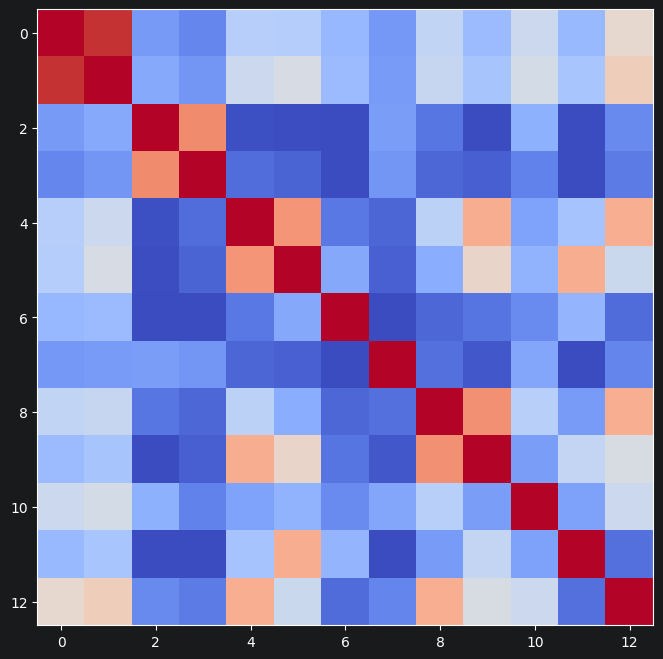

In [13]:
correlation = cleaned.corr()

plt.figure(figsize=(10,8))
plt.imshow(correlation, cmap = "coolwarm", vmin = 0, vmax = 1)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation")
plt.show()

#### Correlation Matrix

The matrix shows how strongly each pair of features moves together. The features most correlated with **es_trampa_max** are **angle_error_max** (0.47), **angle_error_mean** (0.44), **infinite_ammo_ratio** (0.44), and **ammo_left_min** (0.37). Some features are strongly correlated with each other like **angle_error_mean** and **angle_error_max** (0.95), **speed_mean** and **speed_max** (0.78), and **ammo_left_min** and **ammo_max** (0.77). This tells us that they carry similar information to each other.

### Observations and Challenges

#### How EDA Helped in Model Training

Balanced classes: The split is very close to 50/50, so the model would not require adding or subtracting samples or instances.
<br>Skewed Features: Observing the dataset, many features have a lot of zeros, resulting in a positive skew distribution. For example, **angle_error_mean** has a mean of 0.093, but its median is at 0.007. Most normal players stay near zero, and the higher values mostly come from cheaters.

#### Impact on Naive Bayes

Gaussian Naive Bayes assumes each feature follows a normal distribution and that features are independent. The previous graphs show that the results are heavily skewed with zero-heavy features. The correlation between **angle_error_mean** and **angle_error_max** also breaks the independency rule because of its correlation value being 0.95. Because of this, Naive Bayes is expected to perform worse, especially at telling apart cheaters whos values stay close to zero like normal players.

#### Impact on Decision Trees

Decision trees split on thresholds, choosing the features that best separate the two classes into purer groups. 

When features are correlated, such as **angle_error_mean** and **angle_error_max**, the tree may rely more on one of them, so the other can end up with a lower importance score even though it carries similar information.

Since classes are balanced, accuracy is a reliable metric, but precision, recall, and F1-score will also be reported to show how many cheaters are missed or falsely flagged.

# Dataset Split

In [ ]:
x = cleaned.drop(columns = "es_trampa_max")
y = cleaned["es_trampa_max"]

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size = 0.30, random_state = SEED, stratify = y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size = 0.50, random_state = SEED, stratify = y_temp)

x contains all features while y contains **es_trampa_max**. The data was split twice to get 70/15/15. The first split keeps 70% of training and holds the 30% in a temporary set. The second split cuts the temporary set in half to give both the validation set and training set a 15% split. Both split functions use stratify so every set keeps about 48.5% of Cheaters. Both also use **random_state = SEED** so the split comes out the same every time.

In [ ]:
splits = {"Train": y_train, "Validation": y_val, "Test": y_test}

summary = pd.DataFrame({
    name: {
        "Rows": len(s),
        "Not Cheating": (s == 0).sum(),
        "Cheating": (s == 1).sum(),
        "% Cheating": round(s.mean() * 100, 2)
    }
    for name, s in splits.items()
}).T

print(summary)

The Cheating share stays between 48.39% and 48.58% in all three sets, close to the 48.52% in the cleaned dataset. This confirms the stratified split kept the classes balanced.

In [ ]:
pd.concat([x_train, y_train], axis=1).to_csv("trainSet.csv", index=False)
pd.concat([x_val, y_val], axis=1).to_csv("validationSet.csv", index=False)
pd.concat([x_test, y_test], axis=1).to_csv("testSet.csv", index=False)

Each set is saved as its own CSV so both models are trained and tested on exactly the same rows.

## Data Leakage Prevention

1. The timestamp and the four sub-labels were removed before splitting, so no column gives away the answer.
2. Duplicates were removed before splitting, so the same row cannot be in both the training and test sets.
3. Any scaler will be fitted on the training set only, then applied to validation and test.
4. The validation set is used to tune hyperparameters. The test set is used only once, for the final evaluation.

## Limitation

Each row summarizes only 2 seconds of one player's game, so one play session is split into many back-to-back rows. Rows from the same moment look almost the same because the player's speed, aim, and health would barely change in seconds. A random split can place one of these rows in training and the next in testing, which is a form of data leakage. The model is then tested on rows it has nearly seen before, so the test score may be higher than its true performance on new players and could hide overfitting.

# Model training

## Naive Bayes

The first machine learning model utilized in this project was the Gaussian Naive Bayes model. This model is a supervised machine learning model which uses the Bayes’ Theorem in order to calculate the probability that a particular instance belongs to a certain label.

It has the following assumptions:

1. That all numerical features follow a Gaussian distribution within each label.
2. That there is conditional independence between the features given the target label.

This model was chosen due to the Gaussian Naive Bayes model being specifically designed for numerical features while using Gaussian distributions.

## Dataset Preparation

Using the cleaned and separated training and validation datasets, they are loaded into the Gaussian Naive Bayes model for training and evaluation.

Each dataset is then separated into two components: features, which will be used as input for the model, and the labels (es_trampa_max) which are the target outputs the model is trying to predict.


In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
train_data = pd.read_csv("trainSet.csv")
gnbX_T_Train, gnbY_T_Train = train_data.drop(columns = ["es_trampa_max"]), train_data["es_trampa_max"]

validation_data = pd.read_csv("validationSet.csv")
gnbX_Validate, gnbY_Validate = validation_data.drop(columns = ["es_trampa_max"]), validation_data["es_trampa_max"]

## Initial Gaussian Naive Bayes Model

The Gaussian Naive Bayes model is initialized using methods from Scikit-learn. GaussianNB() was used to initialize the model, with the .fit() method used for training using features and labels gathered from the training dataset.

While training, the model is estimating the probability distributions of the features for each target label. This allows it to make predictions for instances it may not have recorded previously such as those in the validation and test datasets.


In [ ]:
gaussianModel_Train = GaussianNB()
gaussianModel_Train.fit(gnbX_T_Train, gnbY_T_Train)

## Training Dataset Evaluation

After being trained, the model is evaluated using the same training dataset to test if it really learned the patterns within its data.

The .predict() method is then used to generate the labels the model has predicted which are then compared to the original target labels with the classification_report() method. This will provide the information concerning precision, recall, F1-Score, and support for each class.


In [ ]:
gnbY_T_Prediction = gaussianModel_Train.predict(gnbX_T_Train)
print(classification_report(gnbY_T_Train, gnbY_T_Prediction))

## Validation Dataset Evaluation

The now trained model is then evaluated using the validation dataset. The validation dataset was not used during training to adequately test how well the model is able to generalize any unknown instances.

 Comparing the difference in the model’s performance between validation and training will allow us to see its classification effectiveness.


In [ ]:
gnbY_V_Prediction = gaussianModel_Train.predict(gnbX_Validate)
print(classification_report(gnbY_Validate, gnbY_V_Prediction))

## var_smoothing Hyperparameter Comparison And Testing

The var_smoothing parameter helps us prevent numerical errors or instability when the Gaussian Naive Bayes model calculates probabilities by adding a small portion of the largest variance across all features.

Different values were tested to determine whether or not adjusting the value would affect the model’s classification performance.


Test 1: var_smoothing value = 1e-9

In [ ]:
gaussianModel_paramTesting_1 = GaussianNB(var_smoothing=1e-9)
gaussianModel_paramTesting_1.fit(gnbX_T_Train, gnbY_T_Train)

In [ ]:
paramTesting_Prediction_1 = gaussianModel_paramTesting_1.predict(gnbX_Validate)
param_probability1 = gaussianModel_paramTesting_1.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_1))

Test 2: var_smoothing value = 1e-8

In [ ]:
gaussianModel_paramTesting_2 = GaussianNB(var_smoothing=1e-8)
gaussianModel_paramTesting_2.fit(gnbX_T_Train, gnbY_T_Train)

In [ ]:
paramTesting_Prediction_2 = gaussianModel_paramTesting_2.predict(gnbX_Validate)
param_probability2 = gaussianModel_paramTesting_2.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_2))

Test 3: var_smoothing value = 1e-7

In [ ]:
gaussianModel_paramTesting_3 = GaussianNB(var_smoothing=1e-7)
gaussianModel_paramTesting_3.fit(gnbX_T_Train, gnbY_T_Train)

In [ ]:
paramTesting_Prediction_3 = gaussianModel_paramTesting_3.predict(gnbX_Validate)
param_probability3 = gaussianModel_paramTesting_3.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_3))

Test 4: var_smoothing value = 1e-6

In [ ]:
gaussianModel_paramTesting_4 = GaussianNB(var_smoothing=1e-6)
gaussianModel_paramTesting_4.fit(gnbX_T_Train, gnbY_T_Train)

In [ ]:
paramTesting_Prediction_4 = gaussianModel_paramTesting_4.predict(gnbX_Validate)
param_probability4 = gaussianModel_paramTesting_4.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_4))

Test 5: var_smoothing value = 1e-5

In [ ]:
gaussianModel_paramTesting_5 = GaussianNB(var_smoothing=1e-5)
gaussianModel_paramTesting_5.fit(gnbX_T_Train, gnbY_T_Train)

In [ ]:
paramTesting_Prediction_5 = gaussianModel_paramTesting_5.predict(gnbX_Validate)
param_probability5 = gaussianModel_paramTesting_5.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_5))

The predicted probabilities from each configuration of the parameter var_smoothing are now compared to determine whether changing it produces any significant differences in the model’s probability estimate.

The Numpy library’s allclose() function then checks whether the 2 probability arrays are approximately equal to each other while the maximum absolute difference measures the largest difference between them numerically while keeping all outputs positive.


In [ ]:
print(np.allclose(param_probability1, param_probability2))
print(np.allclose(param_probability1, param_probability3))
print(np.allclose(param_probability1, param_probability4))
print(np.allclose(param_probability1, param_probability5))

In [ ]:
Diff_Array1 = param_probability1 - param_probability2
Diff_Array2 = param_probability1 - param_probability3
Diff_Array3 = param_probability1 - param_probability4
Diff_Array4 = param_probability1 - param_probability5

max_Diff1 = np.max(np.abs(Diff_Array1))
max_Diff2 = np.max(np.abs(Diff_Array2))
max_Diff3 = np.max(np.abs(Diff_Array3))
max_Diff4 = np.max(np.abs(Diff_Array4))

print(max_Diff1)
print(max_Diff2)
print(max_Diff3)
print(max_Diff4)



## Hyperparmater Comparison Analysis Using GridSearchCV

Apart from Manual Testing, GridSearchCV was used in order to find the most suitable configuration of var_smoothing for the Gaussian Bayes Model.

It tested the different parameter configurations using a five-fold cross validation and evaluated their performance using a macro F1-score.

Macro F1 was chosen as the evaluation metric because it gives equal weight to both labels when evaluating the model.


In [ ]:
gaussianModel_Grid = GaussianNB()

varSmooth_grid = { 'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5] }
gaussianGS = GridSearchCV(gaussianModel_Grid, varSmooth_grid, cv=5, scoring='f1_macro')

gaussianGS.fit(gnbX_T_Train, gnbY_T_Train)

In [ ]:
gaussianGS.best_params_

In [ ]:
gaussianGS.best_score_

In [ ]:
gaussianGS.cv_results_

## Evaluation of Gaussian Naive Bayes Model with Best Parameters

After testing the hyperparameters, the model with the best configuration is selected using best_estimator and put into a separate variable. This model is then evaluated once again using the validation dataset in order to test its performance on unknown instances.

A classification report, confusion matrix, and accuracy score are used to examine the prediction results.

In [ ]:
best_GaussianGS = gaussianGS.best_estimator_

best_Predictions = best_GaussianGS.predict(gnbX_Validate)

print(classification_report(gnbY_Validate, best_Predictions))
print(confusion_matrix(gnbY_Validate, best_Predictions))
print(accuracy_score(gnbY_Validate, best_Predictions))

## Final Test Evaluation

The Gaussian Naive Bayes model with the best parameter is now evaluated using the test dataset. It was kept separate from both the training and validation dataset to avoid data leakage.
The classification report, confusion matrix, and accuracy score are used once again to evaluate the model’s final prediction results.


In [ ]:
test_data = pd.read_csv("testSet.csv")
gnbX_actualTest = test_data.drop(columns = ["es_trampa_max"])
gnbY_actualTest = test_data["es_trampa_max"]

actualTest_Predictions = best_GaussianGS.predict(gnbX_actualTest)

print(classification_report(gnbY_actualTest, actualTest_Predictions))
print(confusion_matrix(gnbY_actualTest, actualTest_Predictions))
print(accuracy_score(gnbY_actualTest, actualTest_Predictions))

The optimized Gaussian Naive Bayes model achieved an accuracy of approximately 79.02% on the testing dataset, with a macro F1-score of 0.79.
The model produced was good at identifying non-cheating instances, achieving a recall of 0.99 for class 0 (not cheating).
Its recall for class 1 (cheating) was only 0.58, meaning that it failed to identify a considerable number of actual cheating instances.
The confusion matrix showed 108 false negatives, these were instances incorrectly classified as non-cheating.
This tells us that despite achieving a reasonable overall accuracy, the model still has difficulty identifying actual cheating instances.


## Decision Trees

Since a decision tree is a supervised learning model, and our dataset has a known label (es_trampa_max) for every row, we can apply this method for the chosen dataset. Our goal is binary classification (predicition of Cheating or Not Cheating), which would be predicted using true/false to a numeric feature, wherein we can ask if the value is greater than/less than #, therefore it can be used. 

### Justification

In addition to the above, cheating in the dataset appears as various combinations of features, such as aim error with ammo use, meaning it would be beneficial for the model to answer this using a path of questions which the decision tree model performs.

### Load the Splits

The CSV files are loaded again so the tree uses the exact same rows as the model from before.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

train = pd.read_csv("trainSet.csv")
val = pd.read_csv("validationSet.csv")
test = pd.read_csv("testSet.csv")

x_train, y_train = train.drop(columns = ["es_trampa_max"]), train["es_trampa_max"]
x_val, y_val = val.drop(columns = ["es_trampa_max"]), val["es_trampa_max"]
x_test, y_test = test.drop(columns = ["es_trampa_max"]), test["es_trampa_max"]

print("Train shape:", x_train.shape, y_train.shape)
print("Validation shape:", x_val.shape, y_val.shape)
print("Test shape:", x_test.shape, y_test.shape)

Each file is separated into the features (x) while the label es_trampa_max is y.

### Baseline Tree

The base tree has no limits, therefore, it will keep splitting until every leaf is pure.

Cheating is the positive class, so Recall refers to the share of cheaters caught while Precision is the share of labeled cheaters who were actually cheating.

In [ ]:
def evaluate(model, x, y):
    pred = model.predict(x)
    return{
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1 Score": f1_score(y, pred),
    }

baseline = DecisionTreeClassifier(criterion="gini", random_state=SEED)
baseline.fit(x_train, y_train)

baseline_results = pd.DataFrame({
    "Train": evaluate(baseline, x_train, y_train),
    "Validation": evaluate(baseline, x_val, y_val),
    "Test": evaluate(baseline, x_test, y_test)
}).T

print(baseline_results)
print("Depth: ", baseline.get_depth(), " | Leaves: ", baseline.get_n_leaves())

### Gini Index

In order to find the best 'yes/no' question for the root node, we must calculate the gini index and choose the lowest score. If there is a high train score but the validation score is low, or a deep tree, or too many leaves, then it is counted as overfitting.

### Hyperparameter Tuning

Every combination of criterion, max_depth, and min_samples_leaf is trained on the training set and scored on the validation set. These settings act as the threshold which limit tree depth and the number of samples per leaf.

In [ ]:
rows = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 4, 5, 6, 7, 8, 9, 10, None]:
        for leaf in [1, 5, 10, 20]:
                model = DecisionTreeClassifier(
                    criterion=criterion,
                    max_depth=depth,
                    min_samples_leaf=leaf,
                    random_state=SEED
                )
                model.fit(x_train, y_train)
                rows.append({
                    "Criterion": criterion,
                    "Max Depth": str(depth),
                    "Min Samples Leaf": leaf,
                    "Leaves": model.get_n_leaves(),
                    "Train F1": f1_score(y_train, model.predict(x_train)),
                    "Validation F1": f1_score(y_val, model.predict(x_val)),
                    "Model": model,
                })

tuning = pd.DataFrame(rows).sort_values(["Validation F1", "Leaves"], ascending=[False, True])
print(tuning.drop(columns=["Model"]).head(10).round(4).to_string(index=False))

Rows are ranked by validation F1 and ties go to the tree with fewer leves because a simpler tree is better for generalization.

### Best Model

The top-ranked setting is chosen as the final model. The table compares it with the baseline tree on the validation set.

In [ ]:
best = tuning.iloc[0]

best_model = best["Model"]

print("Criterion:", best["Criterion"], "| Max Depth:", best["Max Depth"], "| Min Samples Leaf:", best["Min Samples Leaf"], "| Leaves:", best["Leaves"])

comparison = pd.DataFrame({
    "Baseline": evaluate(baseline, x_val, y_val),
    "Trained": evaluate(best_model, x_train, y_train),
    "Validation (Tuned)": evaluate(best_model, x_val, y_val)
}).T

print(comparison.round(4).to_string())

If the gap between the Train and Validation is smaller than the baseline's gap, tuning reduced overfitting. Also, if the validation scores are close to the training scores, then that means that the tree generalizes well.

## Final Test Evaluation

The test set is used at the very end, when all tuning is finished in order to give us an unbiased estimate.

In [ ]:
test_pred = best_model.predict(x_test)

print(pd.Series(evaluate(best_model, x_test, y_test)).round(4).to_string())

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Not Cheating", "Cheating"]).plot(cmap="Blues")
plt.title("Decision Tree: Test Set")
plt.show()

In the confusion matrix, rows represent the actual classes while columns represent the predictions.

The top-right cell are false positives while the bottom-left cells are false negatives.

## Visualizing The Tree

Each box shows the yes/no question, the Gini value, the number of samples, and the class counts.

The left branch are the 'yes'-es and the right branch are the 'no'-s.

The color shows the majority class and gets darker as the box becomes purer.

In [ ]:
plt.figure(figsize=(30, 12))

plot_tree(best_model, feature_names=x_train.columns, class_names=["Not Cheating", "Cheating"], filled=True, rounded=True, max_depth=3, fontsize = 10, precision = 2)

plt.show()

Only the top 3 levels are drawn so that the tree is easily digestable.

## Feature Importance

Feature importancce adds up how much each feature lowered the Gini impurity across all of its splits, normalized to 1.

In [ ]:
importance = pd.Series(best_model.feature_importances_, index=x_train.columns)

importance = importance.sort_values()

importance.plot(kind="barh", figsize=(8, 6), title="Feature Importance")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(4).to_string())

The top features with longer bars are the ones which the tree relies on the most. These can be compared with the EDA, where certain groups showed the largest gaps between cheateres and non-cheaters.

## Error Analysis

### Gaussian Naive Bayes model
achieved an accuracy of 86%. With an overall good performance but some classification errors. Correctly identifying all non-cheaters. But with 79% precision, this indicates that some cheater samples were incorrectly classified as non-cheaters. the cheaters label, the model achieved perfect precision, but has a lower recall of 67%, meaning it failed to detect actual cheaters.

In [ ]:
cm = confusion_matrix(gnbY_actualTest, actualTest_Predictions)

cm_df = pd.DataFrame(cm, index = ["Actual 0", "Actual 1"], columns = ["Predicted 0", "Predicted 1"])

print(cm_df)

The confusion matrix shows that the Gaussian Naive Bayes model correctly classified 269 non-cheaters and 146 cheaters. While misclassifying 111 cheaters as non cheaters and 3 non-cheaters as cheaters. Indicating that the model is highly effective at avoiding false accusations but is less successful at detecting cheating instances.